# M3 を使った Sampler プリミティブの読み出しエラー緩和

*使用量の目安: Heron r2 プロセッサで 1 分未満（注意: これはあくまで目安です。実際の実行時間は異なる場合があります。）*

## 背景

Estimator プリミティブとは異なり、Sampler プリミティブにはエラー緩和の機能が組み込まれていません。
Estimator がサポートする手法のいくつかは期待値のために特化して設計されているため、Sampler プリミティブには適用できません。例外は読み出しエラー緩和です。これは非常に効果的な手法であり、Sampler プリミティブにも適用できます。

[M3 Qiskit アドオン](https://qiskit.github.io/qiskit-addon-mthree/) は、読み出しエラー緩和の効率的な手法を実装しています。このチュートリアルでは、M3 Qiskit アドオンを使って Sampler プリミティブの読み出しエラーを緩和する方法を説明します。

### 読み出しエラーとは

測定の直前、量子ビットレジスターの状態は、計算基底状態の重ね合わせ、または密度行列で記述されます。
量子ビットレジスターを古典ビットレジスターへ測定する過程は、2 つのステップで進みます。
まず、本来の意味での量子測定が行われます。
これは、量子ビットレジスターの状態が、$1$ と $0$ の列で特徴付けられる 1 つの基底状態へ射影されることを意味します。
2 つ目のステップでは、この基底状態を特徴付けるビット列を読み取り、古典コンピューターのメモリーへ書き込みます。
このステップを*読み出し*と呼びます。
実は、2 つ目のステップ（読み出し）の方が、1 つ目のステップ（基底状態への射影）よりも大きなエラーを生じます。
これは、読み出しでは微視的な量子状態を検出し、それを巨視的な領域まで増幅する必要があることを思い出せば、納得がいくでしょう。読み出し共振器は（トランズモン）量子ビットと結合しており、そのためにごくわずかな周波数シフトを受けます。次にマイクロ波パルスを共振器に当てて反射させると、今度はパルスの特性にわずかな変化が生じます。反射したパルスは増幅され、解析されます。これは繊細な過程であり、さまざまなエラーの影響を受けます。

重要な点は、量子測定と読み出しはどちらもエラーの影響を受けるものの、支配的なエラーを生じるのは後者だということです。これを読み出しエラーと呼び、このチュートリアルではこれに焦点を当てます。


### 理論的背景

サンプリングされたビット列（古典メモリーに格納されたもの）が、射影された量子状態を特徴付けるビット列と異なる場合、読み出しエラーが起きたといいます。
これらのエラーはランダムで、サンプルごとに相関がないことが観測されています。
読み出しエラーは*ノイズのある古典チャネル*としてモデル化すると有用であることがわかっています。
つまり、ビット列 $i$ と $j$ のすべての組について、真の値 $j$ が誤って $i$ と読み取られる確率が一定の値で存在するということです。

より正確には、ビット列のすべての組 $(i, j)$ について、真の値が $j$ であるときに $i$ が読み取られる（条件付き）確率 ${M}_{i,j}$ が存在します。
すなわち、

$$
    {M}_{i,j} =  \Pr(\text{readout value is } i | \text{true value is } j)
    \text{ for } i,j \in (0,...,2^n - 1), \tag{1}
$$

ここで $n$ は読み出しレジスターのビット数です。
具体的にするため、$i$ は 10 進数の整数であり、その 2 進表現が計算基底状態のラベルとなるビット列であるとします。
$2^n \times 2^n$ 行列 ${M}$ を*割り当て行列*（assignment matrix）と呼びます。
真の値 $j$ を固定すると、ノイズを含むすべての結果 $i$ について確率を足し合わせた値は $1$ になるはずです。つまり、

$$
    \sum_{i=0}^{2^n - 1} {M}_{i,j} = 1 \text{ for all } j
$$

負の成分を持たず、(1) を満たす行列を*左確率行列*（left-stochastic matrix）と呼びます。
左確率行列は、各列の和が $1$ になることから、*列確率行列*（column-stochastic matrix）とも呼ばれます。
各要素 ${M}_{i,j}$ の近似値は、各基底状態 $|j \rangle$ の準備を繰り返し、サンプリングされたビット列の出現頻度を計算することで実験的に決定します。

出力ビット列の確率分布を繰り返しサンプリングによって推定する実験であれば、${M}$ を使って分布のレベルで読み出しエラーを緩和できます。
最初のステップは、対象とする固定の回路を何度も繰り返し実行し、サンプリングされたビット列のヒストグラムを作ることです。
正規化したヒストグラムは、$2^n$ 通りのビット列についての測定された確率分布であり、これを ${\tilde{p}} \in \mathbb{R}^{2^n}$ と表します。
ビット列 $i$ がサンプリングされる（推定）確率 ${{\tilde{p}}}_i$ は、すべての真のビット列 $j$ について、それが $i$ と取り違えられる確率で重み付けした和に等しくなります。
これを行列の形で書くと、

$$
    {\tilde{p}} = {M} {\vec{p}}, \tag{2},
$$

となります。ここで ${\vec{p}}$ は真の分布です。言い換えると、読み出しエラーは、ビット列の理想的な分布 ${\vec{p}}$ に割り当て行列 ${M}$ を掛けて、観測される分布 ${\tilde{p}}$ を生み出す効果を持ちます。
${\tilde{p}}$ と ${M}$ は測定済みですが、${\vec{p}}$ には直接アクセスできません。原理的には、式 (2) を ${\vec{p}}$ について数値的に解くことで、回路のビット列の真の分布が得られます。

先に進む前に、この素朴な手法のいくつかの重要な特徴に触れておきます。

* 実際には、式 (2) は ${M}$ の逆行列を求めて解くわけではありません。ソフトウェアライブラリーの線形代数ルーチンは、より安定で、正確で、効率的な手法を用います。
* ${M}$ を推定するときには、読み出しエラーだけが起きると仮定しました。特に、状態準備のエラーや量子測定のエラーはない、あるいは少なくとも別の方法で緩和されていると仮定しています。
  この仮定がよく成り立つ範囲で、${M}$ は本当に読み出しエラーだけを表します。しかし、測定されたビット列の分布を補正するために ${M}$ を*使う*ときには、そのような仮定は置きません。実際、興味のある回路はノイズ（たとえばゲートエラー）を持ち込むと予想されます。「真の」分布には、別の方法で緩和されていないあらゆるエラーの影響が依然として含まれます。

この手法は状況によっては有用ですが、いくつかの制約があります。

${M}$ を推定するのに必要な空間と時間のリソースは、$n$ について指数関数的に増大します。

* ${M}$ と ${\tilde{p}}$ の推定は、有限回のサンプリングによる統計誤差を伴います。
  このノイズは、ショット数を増やすことで望むだけ小さくできます（ただし、${M}$ に系統誤差をもたらすハードウェアパラメーターのドリフトの時間スケールまでです）。
  しかし、緩和を行う際に観測されるビット列について何も仮定しない場合、${M}$ の推定に必要なショット数は、少なくとも $n$ について指数関数的に増大します。
* ${M}$ は $2^n \times 2^n$ 行列です。
  $n>10$ になると、${M}$ を格納するのに必要なメモリー量は、高性能なノートパソコンで利用できるメモリー量を超えます。

さらに、次のような制約もあります。

* 復元された分布 ${\vec{p}}$ には、1 つ以上の負の確率が含まれることがあります（ただし、合計は 1 のままです）。解決策の 1 つは、${\vec{p}}$ の各成分が非負であるという制約のもとで $||{M} {\vec{p}} - {\tilde{p}}||^2$ を最小化することです。しかし、このような手法の実行時間は、式 (2) を直接解く場合よりも桁違いに長くなります。
* この緩和の手順は、ビット列の確率分布のレベルで機能します。特に、観測された個々のビット列のエラーを補正することはできません。


### Qiskit M3 アドオン: より長いビット列へのスケーリング

標準的な数値線形代数ルーチンを使って式 (2) を解く方法は、およそ 10 ビット以下のビット列に限られます。一方、M3 ははるかに長いビット列を扱えます。これを可能にしている M3 の 2 つの重要な性質は次のとおりです。

* ビットの集まりの間にある 3 次以上の読み出しエラーの相関は無視できると仮定し、考慮しません。原理的には、ショット数を増やせば、より高次の相関も推定できます。
* ${M}$ を明示的に構築する代わりに、${\tilde{p}}$ を構築するときに収集されたビット列についてだけ確率を記録する、はるかに小さな実効的な行列を使います。

大まかには、手順は次のように進みます。

まず、${M}$ の簡略化された実効的な記述を組み立てるための構成要素を作ります。
次に、対象の回路を繰り返し実行してビット列を収集し、それを使って ${\tilde{p}}$ と、構成要素を用いた実効的な ${M}$ の両方を構築します。

より正確には、次のとおりです。

* 量子ビットごとに 1 量子ビットの割り当て行列を推定します。そのために、量子ビットレジスターをすべて 0 の状態 $|0 ... 0 \rangle$ に、続いてすべて 1 の状態 $|1 ... 1 \rangle$ に準備することを繰り返し、各量子ビットが誤って読み取られる確率を記録します。
* 3 次以上の相関は無視できると仮定し、考慮しません。

  代わりに、$2 \times 2$ の 1 量子ビット割り当て行列を $n$ 個と、$4 \times 4$ の 2 量子ビット割り当て行列を $n(n-1)/2$ 個構築します。これらの 1 量子ビットと 2 量子ビットの割り当て行列は、後で使うために保存しておきます。
* 回路を繰り返しサンプリングして ${\tilde{p}}$ を構築した後、${\tilde{p}}$ の構築時にサンプリングされたビット列だけを使って、${M}$ の実効的な近似を構築します。この実効的な行列は、前の項目で説明した 1 量子ビットと 2 量子ビットの行列を使って組み立てます。
  この行列の線形次元は、多くても ${\tilde{p}}$ の構築に使ったショット数の程度であり、完全な割り当て行列 ${M}$ の次元 $2^n$ よりもはるかに小さくなります。

M3 の技術的な詳細については、[*Scalable Mitigation of Measurement Errors on Quantum Computers*](https://journals.aps.org/prxquantum/abstract/10.1103/PRXQuantum.2.040326) を参照してください。


### 量子アルゴリズムへの M3 の適用

M3 の読み出しエラー緩和を、隠れシフト問題に適用します。隠れシフト問題や、[隠れ部分群問題](https://en.wikipedia.org/wiki/Hidden_subgroup_problem) のような密接に関連する問題は、もともとフォールトトレラントな設定で考案されました（より正確には、フォールトトレラントな QPU が実現可能であることが証明される前に！）。しかし、現在利用可能なプロセッサーでも研究されています。127 量子ビットの IBM® QPU 上で、隠れシフト問題の変種について得られたアルゴリズム上の指数関数的な高速化の例は、[こちらの論文](https://journals.aps.org/prx/accepted/a9074K06A8e1590147da9c69f8c4b64c28247be5a)（[arXiv 版](https://arxiv.org/abs/2401.07934)）で見ることができます。

以下では、すべての演算はブール演算です。
つまり、$a, b \in \mathbb{Z}_2 = \{0, 1\}$ について、加算 $a + b$ は論理 XOR 関数です。
さらに、乗算 $a \times b$（または $a b$）は論理 AND 関数です。$x, y \in \{0, 1\}^n$ については、$x + y$ をビットごとの XOR の適用で定義します。
内積 $\cdot: {\mathbb{Z}_2^n} \rightarrow \mathbb{Z}_2$ は $x \cdot y = \sum_i x_i y_i$ で定義します。


#### アダマール演算子とフーリエ変換

量子アルゴリズムを実装する際には、アダマール演算子をフーリエ変換として使うことがよくあります。
計算基底状態は*古典状態*と呼ばれることもあります。これらは古典的なビット列と 1 対 1 に対応しています。
古典状態に作用する $n$ 量子ビットのアダマール演算子は、ブール超立方体上のフーリエ変換と見なせます。

$$
H^{\otimes n} =  \frac{1}{\sqrt{2^n}} \sum_{x,y \in {\mathbb{Z}_2^n}} (-1)^{x \cdot y} {|{y}\rangle}{\langle{x}|}.
$$

固定したビット列 $s$ に対応する状態 ${|{s}\rangle}$ を考えます。
$H^{\otimes n}$ を作用させ、${\langle {x}|{s}\rangle} = \delta_{x,s}$ を使うと、${|{s}\rangle}$ のフーリエ変換は次のように書けることがわかります。

$$
   H^{\otimes n} {|{s}\rangle} =  \frac{1}{\sqrt{2^n}} \sum_{y \in {\mathbb{Z}_2^n}} (-1)^{s \cdot y} {|{y}\rangle}.
$$

アダマールはそれ自身が逆演算子です。つまり、$H^{\otimes n} H^{\otimes n} = (H H)^{\otimes n} = I^{\otimes n}$ です。
したがって、逆フーリエ変換は同じ演算子 $H^{\otimes n}$ です。
具体的に書くと、次のようになります。

$$
  {|{s}\rangle} =  H^{\otimes n} H^{\otimes n} {|{s}\rangle}  =  H^{\otimes n} \frac{1}{\sqrt{2^n}} \sum_{y \in {\mathbb{Z}_2^n}} (-1)^{s \cdot y} {|{y}\rangle}.
$$


#### 隠れシフト問題

*隠れシフト問題*の簡単な例を考えます。
この問題は、関数への入力に加えられた一定のシフトを特定するものです。
ここで考える関数は内積です。これは、以下で示すものと同様の手法によって隠れシフト問題で量子的な高速化が得られる、大きな関数のクラスのうち最も単純なものです。

$x,y \in {\mathbb{Z}_2^m}$ を長さ $m$ のビット列とします。
${f}: {\mathbb{Z}_2^m} \times {\mathbb{Z}_2^m} \rightarrow \{-1,1\}$ を次のように定義します。

$$
  {f}(x, y) = (-1)^{x \cdot y}.
$$

$a,b \in {\mathbb{Z}_2^m}$ を長さ $m$ の固定したビット列とします。
さらに、$g: {\mathbb{Z}_2^m} \times {\mathbb{Z}_2^m} \rightarrow \{-1,1\}$ を次のように定義します。

$$
  g(x, y) = {f}(x+a, y+b) = (-1)^{(x+a) \cdot (y+b)},
$$

ここで $a$ と $b$ は（隠れた）パラメーターです。
ブラックボックスが 2 つ与えられており、一方は $f$ を、もう一方は $g$ を実装しています。
これらが上で定義した関数を計算することはわかっているものの、$a$ と $b$ はどちらもわからないとします。このゲームの目的は、$f$ と $g$ に問い合わせ（クエリー）を行って、隠れたビット列（シフト）$a$ と $b$ を決定することです。古典的にこのゲームを行う場合、$a$ と $b$ を決定するには $O(2m)$ 回のクエリーが必要なことは明らかです。たとえば、組の一方の要素がすべて 0 で、もう一方の要素がちょうど 1 つの成分だけ $1$ であるような文字列の組すべてについて、$g$ に問い合わせればよいでしょう。
各クエリーで、$a$ または $b$ のどちらかの成分が 1 つわかります。
しかし、ブラックボックスが量子回路として実装されている場合には、$f$ と $g$ にそれぞれ 1 回ずつ問い合わせるだけで $a$ と $b$ を決定できることを見ていきます。

アルゴリズムの計算量の文脈では、ブラックボックスを*オラクル*と呼びます。
オラクルは中身が見えないことに加えて、入力を受け取って瞬時に出力を生成し、それが組み込まれたアルゴリズムの計算量には何も加えないという性質を持ちます。実際、今回の場合、$f$ と $g$ を実装するオラクルは効率的であることがわかります。


#### $f$ と $g$ の量子回路

$f$ と $g$ を量子回路として実装するには、次の材料が必要です。

$x_1,y_1 \in \mathbb{Z}_2$ である 1 量子ビットの古典状態 ${|{x_1}\rangle}, {|{y_1}\rangle}$ について、制御 $Z$ ゲート ${CZ}$ は次のように書けます。

$$
{CZ} {|{x_1}\rangle}{|{y_1}\rangle}{x_1} = (-1)^{x_1 y_1} {|{x_1}\rangle}{x_1}{|{y_1}\rangle}.
$$

$m$ 個の CZ ゲートを、$(x_1, y_1)$ に 1 つ、$(x_2, y_2)$ に 1 つというように、$(x_m, y_m)$ まで作用させます。
この演算子を ${CZ}_{x,y}$ と呼びます。

$U_f = {CZ}_{x,y}$ は ${f} = {f}(x,y)$ の量子版です。

$$
%\CZ_{x,y} {|#1\rangle}{z} =
U_f {|{x}\rangle}{|{y}\rangle} = {CZ}_{x,y} {|{x}\rangle}{|{y}\rangle} = (-1)^{x \cdot y}  {|{x}\rangle}{|{y}\rangle}.
$$

ビット列のシフトも実装する必要があります。
$x$ レジスター上の演算子 $X^{a_1}\cdots X^{a_m}$ を $X_a$ と表し、同様に $y$ レジスター上では $X_b =  X^{b_1}\cdots X^{b_m}$ と表します。
これらの演算子は、ビットが $1$ のところには $X$ を、$0$ のところには恒等演算子 $I$ を作用させます。
すると、次のようになります。

$$
 X_a X_b  {|{x}\rangle}{|{y}\rangle} = {|{x+a}\rangle}{|{y+b}\rangle}.
$$

2 つ目のブラックボックス $g$ は、次のユニタリー $U_g$ で実装されます。

$$
%U_g {|{x}\rangle}{|{y}\rangle} = X_aX_b \CZ_{x,y} X_aX_b {|{x}\rangle}{|{y}\rangle}.
U_g = X_aX_b {CZ}_{x,y} X_aX_b.
$$

これを確かめるため、演算子を右から左へ順に状態 ${|{x}\rangle}{|{y}\rangle}$ に作用させます。
まず、

$$
 X_a X_b  {|{x}\rangle}{|{y}\rangle} = {|{x+a}\rangle}{|{y+b}\rangle}.
$$

次に、

$$
  {CZ}_{x,y}  {|{x+a}\rangle}{|{y+b}\rangle} = (-1)^{(x+a)\cdot (y+b)} {|{x+a}\rangle}{|{y+b}\rangle}.
$$

最後に、

$$
  X^a X^b (-1)^{(x+a)\cdot (y+b)} {|{x+a}\rangle}{|{y+b}\rangle} = (-1)^{(x+a)\cdot (y+b)} {|{x}\rangle}{|{y}\rangle},
$$

となり、これは確かに $f(x+a, y+b)$ の量子版です。


#### 隠れシフトアルゴリズム

ここまでの部品を組み合わせて、隠れシフト問題を解きます。
まず、すべて 0 の状態に初期化されたレジスターにアダマールを作用させます。

$$
H^{\otimes 2m} = H^{\otimes m} \otimes H^{\otimes m} {{|{0}\rangle}^{\otimes m}}{{|{0}\rangle}^{\otimes m}} = \frac{1}{\sqrt{2^{2m}}} \sum_{x, y \in {\mathbb{Z}_2^m}} (-1)^{x \cdot y} {|{x}\rangle}{|{y}\rangle}.
$$

次に、オラクル $g$ に問い合わせると、次の状態が得られます。

$$
U_g H^{\otimes 2m} {{|{0}\rangle}^{\otimes m}}{{|{0}\rangle}^{\otimes m}}
= \frac{1}{\sqrt{2^{2m}}} \sum_{x, y \in {\mathbb{Z}_2^m}} (-1)^{(x+a) \cdot (y+b)} {|{x}\rangle}{|{y}\rangle}
$$

$$
\approx \frac{1}{\sqrt{2^{2m}}} \sum_{x, y \in {\mathbb{Z}_2^m}} (-1)^{x \cdot y + x \cdot b + y \cdot a} {|{x}\rangle}{|{y}\rangle}.
$$

最後の行では、定数のグローバル位相因子 $(-1)^{a \cdot b}$ を省略し、位相を除いた等号を $\approx$ で表しています。
次に、オラクル $f$ を作用させると、もう 1 つの因子 $(-1)^{x \cdot y}$ が加わり、すでにある因子と打ち消し合います。すると、次のようになります。

$$
U_f U_g H^{\otimes 2m} {{|{0}\rangle}^{\otimes m}}{{|{0}\rangle}^{\otimes m}}
\approx \frac{1}{\sqrt{2^{2m}}} \sum_{x, y \in {\mathbb{Z}_2^m}} (-1)^{x \cdot b + y \cdot a} {|{x}\rangle}{|{y}\rangle}.
$$

最後のステップは、逆フーリエ変換 $H^{\otimes 2m} = H^{\otimes m} \otimes H^{\otimes m}$ を作用させることで、その結果は次のようになります。

$$
H^{\otimes 2m} U_f U_g  H^{\otimes 2m} {{|{0}\rangle}^{\otimes m}}{{|{0}\rangle}^{\otimes m}}
\approx {|{b}\rangle}{|{a}\rangle}.
$$

これで回路は完成です。ノイズがない場合、量子レジスターをサンプリングすると、確率 $1$ でビット列 $b, a$ が返されます。

ブール内積は、いわゆるベント関数（bent function）の一例です。
ここではベント関数を定義せず、ベント関数が「入力のある線形部分空間への出力の依存性を利用しようとする攻撃に対して最大限の耐性を持つ」ことだけを述べておきます。
この引用は論文 [*Quantum algorithms for highly non-linear Boolean functions*](https://arxiv.org/abs/0811.3208) からのもので、この論文ではいくつかのクラスのベント関数について効率的な隠れシフトアルゴリズムが示されています。
このチュートリアルのアルゴリズムは、この論文の 3.1 節に登場します。

より一般的な場合、隠れシフト $s \in \mathbb{Z}^n$ を求める回路は次のとおりです。

$$
 H^{\otimes n} U_{\tilde{f}}  H^{\otimes n} U_g  H^{\otimes n} {|{0}\rangle}^{\otimes n} = {|{s}\rangle}.
$$

一般的な場合、$f$ と $g$ は 1 変数の関数です。
今回の内積の例は、$f(x, y) \to f(z)$ とし、$z$ を $x$ と $y$ を連結したもの、$s$ を $a$ と $b$ を連結したものとすれば、この形になります。
一般的な場合には、ちょうど 2 つのオラクルが必要です。1 つは $g$ のオラクル、もう 1 つは $\tilde{f}$ のオラクルで、後者はベント関数 $f$ の*双対*（dual）と呼ばれる関数です。
内積関数は、$\tilde{f}=f$ という自己双対の性質を持ちます。

内積の隠れシフトを求める今回の回路では、一般的な場合の回路に現れる中央のアダマールの層を省略しました。一般的な場合にはこの層が必要ですが、省略することで回路の深さを少し節約しました。その代わり、出力が望ましい ${|{a}\rangle}{|{b}\rangle}$ ではなく ${|{b}\rangle}{|{a}\rangle}$ になるため、少しの後処理が必要になります。


## 要件

このチュートリアルを始める前に、次のものがインストールされていることを確認してください。

* Qiskit SDK v2.1 以降（[可視化](/docs/api/qiskit/visualization) サポート付き）
* Qiskit Runtime v0.41 以降（`pip install qiskit-ibm-runtime`）
* M3 Qiskit アドオン v3.0（`pip install mthree`）


## セットアップ


In [1]:
from collections.abc import Iterator, Sequence
from random import Random
from qiskit.circuit import (
    CircuitInstruction,
    QuantumCircuit,
    QuantumRegister,
    Qubit,
)
from qiskit.circuit.library import CZGate, HGate, XGate
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
import timeit
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import SamplerV2 as Sampler
import mthree

## ステップ 1: 古典的な入力を量子問題へマッピングする


まず、隠れシフト問題を `QuantumCircuit` として実装する関数を書きます。


In [2]:
def apply_hadamards(qubits: Sequence[Qubit]) -> Iterator[CircuitInstruction]:
    """すべての量子ビットにアダマールゲートを作用させる"""
    for q in qubits:
        yield CircuitInstruction(HGate(), [q], [])


def apply_shift(
    qubits: Sequence[Qubit], shift: int
) -> Iterator[CircuitInstruction]:
    """シフトのビットが 1 のところに X ゲートを作用させる"""
    for i, q in zip(range(shift.bit_length()), qubits):
        if shift >> i & 1:
            yield CircuitInstruction(XGate(), [q], [])


def oracle_f(qubits: Sequence[Qubit]) -> Iterator[CircuitInstruction]:
    """f オラクルを作用させる"""
    for i in range(0, len(qubits) - 1, 2):
        yield CircuitInstruction(CZGate(), [qubits[i], qubits[i + 1]])


def oracle_g(
    qubits: Sequence[Qubit], shift: int
) -> Iterator[CircuitInstruction]:
    """g オラクルを作用させる"""
    yield from apply_shift(qubits, shift)
    yield from oracle_f(qubits)
    yield from apply_shift(qubits, shift)


def determine_hidden_shift(
    qubits: Sequence[Qubit], shift: int
) -> Iterator[CircuitInstruction]:
    """隠れシフトを決定する"""
    yield from apply_hadamards(qubits)
    yield from oracle_g(qubits, shift)
    # 後処理と引き換えに、この層を省略する
    # yield from apply_hadamards(qubits)
    yield from oracle_f(qubits)
    yield from apply_hadamards(qubits)


def run_hidden_shift_circuit(n_qubits, rng):
    hidden_shift = rng.getrandbits(n_qubits)

    qubits = QuantumRegister(n_qubits, name="q")
    circuit = QuantumCircuit.from_instructions(
        determine_hidden_shift(qubits, hidden_shift), qubits=qubits
    )
    circuit.measure_all()
    # 隠れシフトを文字列に整形する
    hidden_shift_string = format(hidden_shift, f"0{n_qubits}b")
    return (circuit, hidden_shift, hidden_shift_string)


def display_circuit(circuit):
    return circuit.remove_final_measurements(inplace=False).draw(
        "mpl", idle_wires=False, scale=0.5, fold=-1
    )

まずは小さな例から始めます。


隠れシフトの文字列 011010


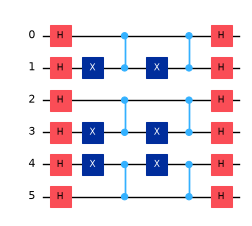

In [3]:
n_qubits = 6
random_seed = 12345
rng = Random(random_seed)
circuit, hidden_shift, hidden_shift_string = run_hidden_shift_circuit(
    n_qubits, rng
)

print(f"隠れシフトの文字列 {hidden_shift_string}")

display_circuit(circuit)

## ステップ 2: 量子ハードウェアでの実行に向けて回路を最適化する


In [4]:
job_tags = [
    f"shift {hidden_shift_string}",
    f"n_qubits {n_qubits}",
    f"seed = {random_seed}",
]
job_tags

['shift 011010', 'n_qubits 6', 'seed = 12345']

使用するバックエンド: ibm_fez


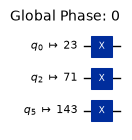

In [5]:
# IBM Cloud 上の量子コンピューターで回路を実行するには、ここのコメントを外す
service = QiskitRuntimeService()
backend = service.least_busy(
    operational=True, simulator=False, min_num_qubits=100
)

# from qiskit_ibm_runtime.fake_provider import FakeMelbourneV2
# backend = FakeMelbourneV2()
# backend.refresh(service)

print(f"使用するバックエンド: {backend.name}")


def get_isa_circuit(circuit, backend):
    pass_manager = generate_preset_pass_manager(
        optimization_level=3, backend=backend, seed_transpiler=1234
    )
    isa_circuit = pass_manager.run(circuit)
    return isa_circuit


isa_circuit = get_isa_circuit(circuit, backend)
display_circuit(isa_circuit)

## ステップ 3: Qiskit プリミティブを使って回路を実行する


In [6]:
# Sampler プリミティブを使って隠れシフト問題を解くジョブを送信する
NUM_SHOTS = 50_000


def run_sampler(backend, isa_circuit, num_shots):
    sampler = Sampler(mode=backend)
    sampler.options.environment.job_tags
    pubs = [(isa_circuit, None, NUM_SHOTS)]
    job = sampler.run(pubs)
    return job


def setup_mthree_mitigation(isa_circuit, backend):
    # mthree がどの量子ビットをキャリブレーションすればよいかわかるように、最終的な量子ビットのマッピングを取得する
    qubit_mapping = mthree.utils.final_measurement_mapping(isa_circuit)

    # 読み出しエラーのキャリブレーション用のジョブを送信する
    mit = mthree.M3Mitigation(backend)
    mit.cals_from_system(qubit_mapping, rep_delay=None)

    return mit, qubit_mapping

In [7]:
job = run_sampler(backend, isa_circuit, NUM_SHOTS)
mit, qubit_mapping = setup_mthree_mitigation(isa_circuit, backend)

## ステップ 4: 後処理を行い、古典的な形式で結果を返す

上の理論的な議論では、入力 $ab$ に対して出力 $ba$ が得られることを確かめました。
さらに 1 つ複雑な点があります。（トランスパイル前の）回路を単純にするため、必要な CZ ゲートを隣り合う量子ビットの組の間に挿入しました。これは、ビット列 $a$ と $b$ を $a1 b1 a2 b2 \ldots$ のように交互に並べることに相当します。
出力文字列 $ba$ も同様に $b1 a1 b2 a2 \ldots$ と交互に並びます。下の関数 `unscramble` は、入力と出力の文字列を直接比較できるように、出力文字列を $b1 a1 b2 a2 \ldots$ から $a1 b1 a2 b2 \ldots$ へ変換します。


In [8]:
# ビット列のカウントを取得する
def get_bitstring_counts(job):
    result = job.result()
    pub_result = result[0]
    counts = pub_result.data.meas.get_counts()
    return counts, pub_result

In [9]:
counts, pub_result = get_bitstring_counts(job)

2 つのビット列の間のハミング距離とは、ビットが異なる位置の数のことです。


In [10]:
def hamming_distance(s1, s2):
    weight = 0
    for c1, c2 in zip(s1, s2):
        (c1, c2) = (int(c1), int(c2))
        if (c1 == 1 and c2 == 1) or (c1 == 0 and c2 == 0):
            weight += 1

    return weight

In [11]:
# a1b1a2b2... という形の文字列を b1a1b2a1... に置き換える
# つまり、連続するビットの組それぞれの順番を逆にする
def unscramble(bitstring):
    ps = [bitstring[i : i + 2][::-1] for i in range(0, len(bitstring), 2)]
    return "".join(ps)


def find_hidden_shift_bitstring(counts, hidden_shift_string):
    # カウントを確率に変換する
    probs = {
        unscramble(bitstring): count / NUM_SHOTS
        for bitstring, count in counts.items()
    }

    # 最も確率の高いビット列を取得する
    most_probable = max(probs, key=lambda x: probs[x])

    print(f"期待される隠れシフトの文字列: {hidden_shift_string}")
    if most_probable == hidden_shift_string:
        print("最も確率の高いビット列が隠れシフトと一致しました 😊。")
    else:
        print("最も確率の高いビット列は隠れシフトと一致しませんでした ☹️。")
    print("上位 10 個のビット列とその確率:")
    display(
        {
            k: (v, hamming_distance(hidden_shift_string, k))
            for k, v in sorted(
                probs.items(), key=lambda x: x[1], reverse=True
            )[:10]
        }
    )

    return probs, most_probable

In [12]:
probs, most_probable = find_hidden_shift_bitstring(
    counts, hidden_shift_string
)

期待される隠れシフトの文字列: 011010
最も確率の高いビット列が隠れシフトと一致しました 😊。
上位 10 個のビット列とその確率:


{'011010': (0.9709, 6),
 '011000': (0.0103, 5),
 '010010': (0.0079, 5),
 '001010': (0.0065, 5),
 '011011': (0.00306, 5),
 '111010': (0.0006, 5),
 '011110': (0.0004, 5),
 '010000': (0.0001, 4),
 '000010': (8e-05, 4),
 '001011': (4e-05, 4)}

M3 による読み出しエラー緩和を適用する前に、最も確率の高いビット列の確率を記録しておきましょう。


In [13]:
max_probability_before_M3 = probs[most_probable]
max_probability_before_M3

0.9709

次に、M3 が学習した読み出しの補正をカウントに適用します。
関数 `apply_corrections` は準確率分布を返します。これは合計が $1$ になる `float` オブジェクトのリストです。ただし、一部の値は負になることがあります。


In [14]:
def perform_mitigation(mit, counts, qubit_mapping):
    # 読み出しエラーを緩和する
    quasis = mit.apply_correction(counts, qubit_mapping)

    # 結果を表示する
    most_probable_after_m3 = unscramble(max(quasis, key=lambda x: quasis[x]))

    is_hidden_shift_identified = most_probable_after_m3 == hidden_shift_string
    if is_hidden_shift_identified:
        print("最も確率の高いビット列が隠れシフトと一致しました 😊。")
    else:
        print("最も確率の高いビット列は隠れシフトと一致しませんでした ☹️。")
    print("上位 10 個のビット列とその準確率:")
    topten = {
        unscramble(k): f"{v:.2e}"
        for k, v in sorted(quasis.items(), key=lambda x: x[1], reverse=True)[
            :10
        ]
    }
    max_probability_after_M3 = float(topten[most_probable_after_m3])
    display(topten)

    return max_probability_after_M3, is_hidden_shift_identified

In [15]:
print(f"期待される隠れシフトの文字列: {hidden_shift_string}")
max_probability_after_M3, is_hidden_shift_identified = perform_mitigation(
    mit, counts, qubit_mapping
)

期待される隠れシフトの文字列: 011010
最も確率の高いビット列が隠れシフトと一致しました 😊。
上位 10 個のビット列とその準確率:


{'011010': '1.00e+00',
 '011000': '3.03e-04',
 '111010': '1.16e-04',
 '000010': '3.06e-05',
 '001011': '1.98e-05',
 '010000': '1.55e-05',
 '110010': '1.49e-05',
 '011001': '7.61e-06',
 '010011': '-4.79e-06',
 '001000': '-2.95e-05'}

#### M3 による補正の適用前と適用後で、隠れシフトの文字列の特定結果を比較する


In [16]:
def compare_before_and_after_M3(
    max_probability_before_M3,
    max_probability_after_M3,
    is_hidden_shift_identified,
):
    is_probability_improved = (
        max_probability_after_M3 > max_probability_before_M3
    )
    print(f"M3 適用前の最大確率: {max_probability_before_M3}")
    print(f"M3 適用後の最大確率: {max_probability_after_M3}")
    if is_hidden_shift_identified and is_probability_improved:
        print("読み出しエラー緩和は効果がありました！ 😊")
    else:
        print("読み出しエラー緩和は効果がありませんでした。 ☹️")

In [17]:
compare_before_and_after_M3(
    max_probability_before_M3,
    max_probability_after_M3,
    is_hidden_shift_identified,
)

M3 適用前の最大確率: 0.9709
M3 適用後の最大確率: 1.0
読み出しエラー緩和は効果がありました！ 😊


### M3 に必要な CPU 時間がショット数に応じてどう増えるかをプロットする


5000 ショットに M3 の補正を適用しています...
	0.01089445801335387 秒で完了しました。
7500 ショットに M3 の補正を適用しています...
	0.009875584015389904 秒で完了しました。
10000 ショットに M3 の補正を適用しています...
	0.00679754200973548 秒で完了しました。
12500 ショットに M3 の補正を適用しています...
	0.007828083995264024 秒で完了しました。
15000 ショットに M3 の補正を適用しています...
	0.008791750005912036 秒で完了しました。
17500 ショットに M3 の補正を適用しています...
	0.011779624997870997 秒で完了しました。
20000 ショットに M3 の補正を適用しています...
	0.01177445802022703 秒で完了しました。
22500 ショットに M3 の補正を適用しています...
	0.01290366699686274 秒で完了しました。
25000 ショットに M3 の補正を適用しています...
	0.013930084009189159 秒で完了しました。
27500 ショットに M3 の補正を適用しています...
	0.01609062499483116 秒で完了しました。
30000 ショットに M3 の補正を適用しています...
	0.016732042015064508 秒で完了しました。
32500 ショットに M3 の補正を適用しています...
	0.018017000023974106 秒で完了しました。
35000 ショットに M3 の補正を適用しています...
	0.01928845900692977 秒で完了しました。
37500 ショットに M3 の補正を適用しています...
	0.021354999975301325 秒で完了しました。
40000 ショットに M3 の補正を適用しています...
	0.022252333990763873 秒で完了しました。
42500 ショットに M3 の補正を適用しています...
	0.023340749990893528 秒で完了しました。
45000 ショットに M3 の

Text(0.5, 1.0, 'M3 の補正の適用にかかる時間')

/Users/kifumi/uv/qiskit_252/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 26178 (\N{CJK UNIFIED IDEOGRAPH-6642}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/kifumi/uv/qiskit_252/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 38291 (\N{CJK UNIFIED IDEOGRAPH-9593}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/kifumi/uv/qiskit_252/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/kifumi/uv/qiskit_252/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/Users/kifumi/uv/qiskit_252/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Glyph 65289 (\N{FULLWIDTH RIGHT PARENTHESIS}) missing from font(s) D

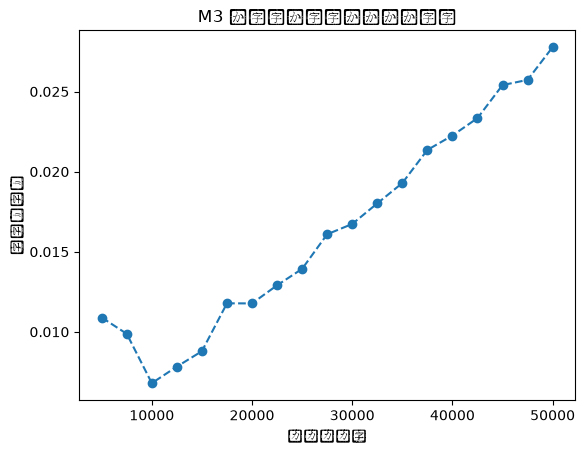

In [18]:
# ショット数を 5000 から 25000 まで変えてサンプルを集める
shots_range = range(5000, NUM_SHOTS + 1, 2500)
times = []
for shots in shots_range:
    print(f"{shots} ショットに M3 の補正を適用しています...")
    t0 = timeit.default_timer()
    _ = mit.apply_correction(
        pub_result.data.meas.slice_shots(range(shots)).get_counts(),
        qubit_mapping,
    )
    t1 = timeit.default_timer()
    print(f"\t{t1 - t0} 秒で完了しました。")
    times.append(t1 - t0)

fig, ax = plt.subplots()
ax.plot(shots_range, times, "o--")
ax.set_xlabel("ショット数")
ax.set_ylabel("時間（秒）")
ax.set_title("M3 の補正の適用にかかる時間")

#### プロットの解釈

上のプロットから、M3 の補正の適用に必要な時間は、ショット数に対して線形に増えることがわかります。


## スケールアップ


In [19]:
n_qubits = 80
rng = Random(12345)
circuit, hidden_shift, hidden_shift_string = run_hidden_shift_circuit(
    n_qubits, rng
)

print(f"隠れシフトの文字列 {hidden_shift_string}")

隠れシフトの文字列 00000010100110101011101110010001010000110011101001101010101001111001100110000111


In [20]:
isa_circuit = get_isa_circuit(circuit, backend)

In [21]:
job = run_sampler(backend, isa_circuit, NUM_SHOTS)
mit, qubit_mapping = setup_mthree_mitigation(isa_circuit, backend)

In [22]:
counts, pub_result = get_bitstring_counts(job)

In [23]:
probs, most_probable = find_hidden_shift_bitstring(
    counts, hidden_shift_string
)

期待される隠れシフトの文字列: 00000010100110101011101110010001010000110011101001101010101001111001100110000111
最も確率の高いビット列が隠れシフトと一致しました 😊。
上位 10 個のビット列とその確率:


{'00000010100110101011101110010001010000110011101001101010101001111001100110000111': (0.2863,
  80),
 '00000010100110101011111110010001010000110011101001101010101001111001100110000111': (0.0217,
  79),
 '00000010100110101011101110010001010000110011101001111010101001111001100110000111': (0.01974,
  79),
 '00000010100110101011101110010001010000100011101001101010101001111001100110000111': (0.0196,
  79),
 '00000010100110101011101010010001010000110011101001101010101001111001100110000111': (0.018,
  79),
 '00000010100110101011101110010001010000110011101001101010100001111001100110000111': (0.01684,
  79),
 '00000010100110101011101110010001010000110011101001101010101001111001101110000111': (0.01612,
  79),
 '00000010100110101011101110010001010000110011101001101010101101111001100110000111': (0.01416,
  79),
 '00000010100110101011101110010001000000110011101001101010101001111001100110000111': (0.01196,
  79),
 '00000010100110111011101110010001010000110011101001101010101001111001100110000111': (0

正しい隠れシフトの文字列が見つかったことがわかります。さらに、次に確率の高い 9 個のビット列は、1 か所だけが間違っています。


最も高い確率を記録します。


In [24]:
max_probability_before_M3 = probs[most_probable]
max_probability_before_M3

0.2863

In [25]:
print(f"期待される隠れシフトの文字列: {hidden_shift_string}")
max_probability_after_M3, is_hidden_shift_identified = perform_mitigation(
    mit, counts, qubit_mapping
)

期待される隠れシフトの文字列: 00000010100110101011101110010001010000110011101001101010101001111001100110000111
最も確率の高いビット列が隠れシフトと一致しました 😊。
上位 10 個のビット列とその準確率:


{'00000010100110101011101110010001010000110011101001101010101001111001100110000111': '9.06e-01',
 '00000010100110101011101110000001010000110011101001101010101001111001100110000111': '3.84e-03',
 '00000010100110101011101110010001010000110011101001101010101001111001100010000111': '2.73e-03',
 '10000010100110101011101110010001010000110011101001101010101001111001100110000111': '2.34e-03',
 '00000010100110001011101110010001010000110011101001101010101001111001100110000111': '2.29e-03',
 '00000010100110101011101110010001110000110011101001101010101001111001100110000111': '1.58e-03',
 '00000010100110101010101110010001010000110011101001101010101001111001100110000111': '1.43e-03',
 '00000010100110101011101110010001010000110011001001101010101001111001100110000111': '1.22e-03',
 '00000010100110101011101110010001010000110011101001101010101001111001100110000011': '1.10e-03',
 '00000010100110101011101110010001010000110010101001101010101001111001100110000111': '1.07e-03'}

In [26]:
compare_before_and_after_M3(
    max_probability_before_M3,
    max_probability_after_M3,
    is_hidden_shift_identified,
)

M3 適用前の最大確率: 0.2863
M3 適用後の最大確率: 0.906
読み出しエラー緩和は効果がありました！ 😊


結果から、読み出しエラーが支配的なエラー源であり、M3 による緩和が効果的だったことがわかります。


© IBM Corp., 2017-2026